# Quantium Virtual Internship — Task 2
## Trial store evaluation

We compare stores **77, 86, and 88** with similar stores. The trial ran from **February to April 2019**. First, we match each trial store to a control store using the seven months before the trial. Then we compare sales and customer counts during the trial.

## 1. Load and prepare the transactions

Use the original transaction workbook. It has correct sales values. The combined workbook may display some sales values as times. As in Task 1, remove the exact duplicate and the two bulk purchases from customer 226000.

In [8]:
print("Starting Task 2. The transaction file has about 265,000 rows, so loading may take 10–15 seconds.", flush=True)

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats


folder = Path.cwd()
print("Reading the transaction spreadsheet...", flush=True)
transactions = pd.read_excel(folder / "QVI_transaction_data.xlsx")
print("Spreadsheet loaded.", flush=True)
transactions["DATE"] = pd.to_datetime(
    transactions["DATE"], unit="D", origin="1899-12-30"
)
transactions = transactions.drop_duplicates().copy()
transactions = transactions[transactions["LYLTY_CARD_NBR"] != 226000].copy()
transactions["MONTH"] = transactions["DATE"].dt.to_period("M")

trial_stores = [77, 86, 88]
trial_start = pd.Period("2019-02", freq="M")
trial_end = pd.Period("2019-04", freq="M")
pre_trial_months = pd.period_range("2018-07", "2019-01", freq="M")
trial_months = pd.period_range(trial_start, trial_end, freq="M")

print("Clean transaction rows:", len(transactions))
print("Months:", transactions["MONTH"].min(), "to", transactions["MONTH"].max())
print("Trial stores:", trial_stores)

Starting Task 2. The transaction file has about 265,000 rows, so loading may take 10–15 seconds.
Reading the transaction spreadsheet...
Spreadsheet loaded.
Clean transaction rows: 264833
Months: 2018-07 to 2019-06
Trial stores: [77, 86, 88]


## 2. Calculate store results by month

For each store and month, calculate total sales, the number of different customers, and the number of different transactions. Missing store-months are filled with zero so all stores use the same months in comparisons.

In [9]:
monthly = transactions.groupby(["STORE_NBR", "MONTH"]).agg(
    sales=("TOT_SALES", "sum"),
    customers=("LYLTY_CARD_NBR", "nunique"),
    transactions=("TXN_ID", "nunique"),
).reset_index()

all_stores = sorted(transactions["STORE_NBR"].unique())
all_months = pd.period_range(
    transactions["MONTH"].min(), transactions["MONTH"].max(), freq="M"
)
complete_index = pd.MultiIndex.from_product(
    [all_stores, all_months], names=["STORE_NBR", "MONTH"]
)
monthly = monthly.set_index(["STORE_NBR", "MONTH"]).reindex(
    complete_index, fill_value=0
).reset_index()
monthly["transactions_per_customer"] = monthly["transactions"] / monthly["customers"].replace(0, np.nan)
monthly["transactions_per_customer"] = monthly["transactions_per_customer"].fillna(0)

print("Store-month rows:", len(monthly))
display(monthly[monthly["STORE_NBR"].isin(trial_stores)].head(9))

Store-month rows: 3264


,STORE_NBR,MONTH,sales,customers,transactions,transactions_per_customer
912,77,2018-07,296.8,51,55,1.078431
913,77,2018-08,255.5,47,48,1.021277
914,77,2018-09,225.2,42,44,1.047619
915,77,2018-10,204.5,37,38,1.027027
916,77,2018-11,245.3,41,44,1.073171
917,77,2018-12,267.3,46,48,1.043478
918,77,2019-01,204.4,35,39,1.114286
919,77,2019-02,235.0,45,45,1.000000
920,77,2019-03,278.5,50,55,1.100000


## 3. Find a control store for each trial store

A useful control store should have a similar sales pattern and a similar average sales level before the trial. We score each candidate using:

1. **Correlation** — how similarly monthly sales and customer counts move.
2. **Size similarity** — how close the average sales and customer counts are.

The two scores are averaged. Trial stores are not allowed to be controls.

In [10]:
import warnings
warnings.filterwarnings("ignore")  # correlation is NaN for flat series; handled in the code

before_trial = monthly[monthly["MONTH"].isin(pre_trial_months)]
control_stores = [store for store in all_stores if store not in trial_stores]
control_map = {}
control_score_tables = {}

for trial_store in trial_stores:
    trial_data = before_trial[before_trial["STORE_NBR"] == trial_store].set_index("MONTH")
    scores = []

    for control_store in control_stores:
        control_data = before_trial[before_trial["STORE_NBR"] == control_store].set_index("MONTH")
        metric_scores = []

        for metric in ["sales", "customers"]:
            trial_values = trial_data[metric]
            control_values = control_data[metric]

            correlation = trial_values.corr(control_values)
            if pd.isna(correlation):
                correlation = 0

            trial_average = trial_values.mean()
            control_average = control_values.mean()
            if trial_average == 0:
                size_similarity = 0
            else:
                size_similarity = max(0, 1 - abs(trial_average - control_average) / trial_average)

            metric_scores.append((correlation + size_similarity) / 2)

        scores.append({
            "control_store": control_store,
            "score": np.mean(metric_scores),
        })

    score_table = pd.DataFrame(scores).sort_values("score", ascending=False)
    best_control = int(score_table.iloc[0]["control_store"])
    control_map[trial_store] = best_control
    control_score_tables[trial_store] = score_table
    print(f"Trial store {trial_store} -> control store {best_control}")
    display(score_table.head())

Trial store 77 -> control store 233


,control_store,score
229,233,0.966929
40,41,0.859323
49,50,0.777096
163,167,0.776959
52,53,0.770091


Trial store 86 -> control store 155


,control_store,score
151,155,0.947475
105,109,0.883855
110,114,0.861995
134,138,0.861560
221,225,0.835560


Trial store 88 -> control store 237


,control_store,score
233,237,0.812142
174,178,0.798157
68,69,0.711717
109,113,0.707610
197,201,0.699751


## 4. Check the pre-trial match

These plots compare sales and customer counts for the seven months before the trial. Similar movement gives us more confidence that the control store is a useful comparison.

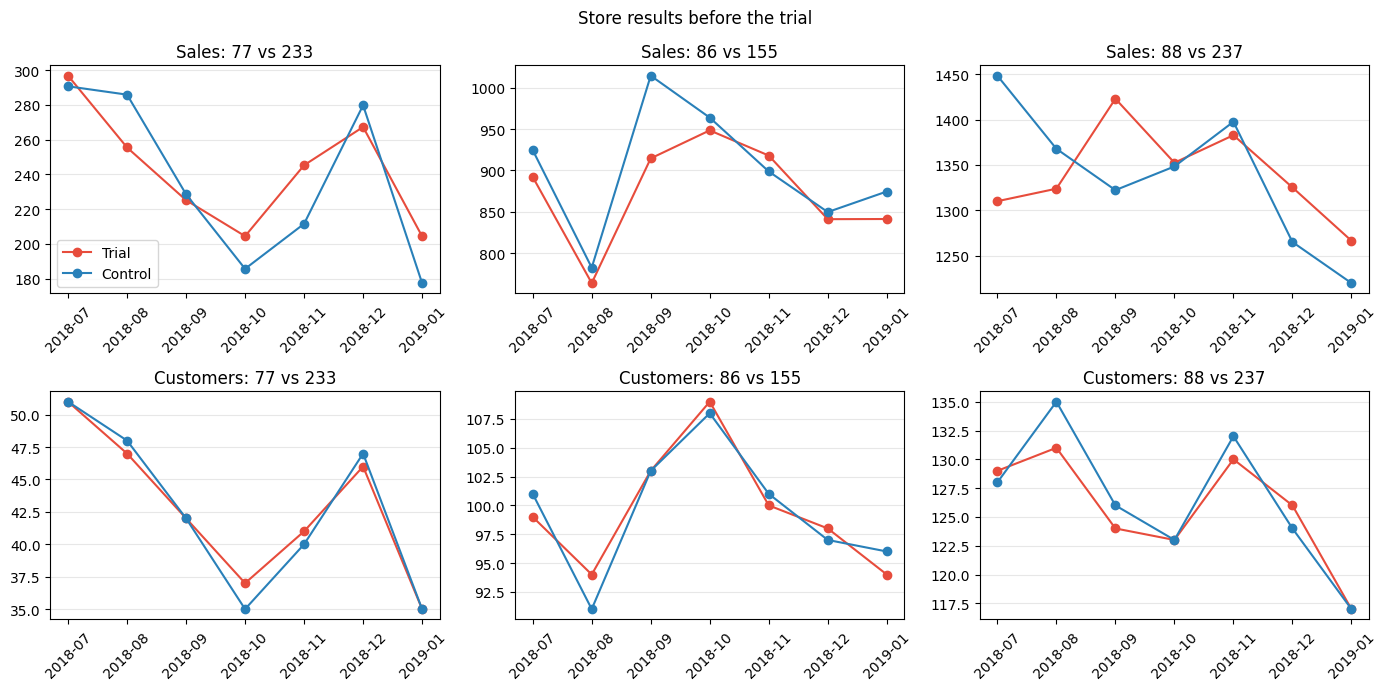

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for column, trial_store in enumerate(trial_stores):
    control_store = control_map[trial_store]

    for row, metric in enumerate(["sales", "customers"]):
        ax = axes[row, column]
        for store, color, label in [
            (trial_store, "#E74C3C", "Trial"),
            (control_store, "#2980B9", "Control"),
        ]:
            values = before_trial[before_trial["STORE_NBR"] == store].sort_values("MONTH")
            ax.plot(values["MONTH"].astype(str), values[metric], marker="o", color=color, label=label)
        ax.set_title(f"{metric.title()}: {trial_store} vs {control_store}")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.3)
        if row == 0 and column == 0:
            ax.legend()

plt.suptitle("Store results before the trial")
plt.tight_layout()
plt.savefig(folder / "task2_fig1_pretrial_similarity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Compare trial stores with their controls

The control store may be larger or smaller than the trial store. We scale the control using the average results from before the trial. The shaded area marks February–April 2019.

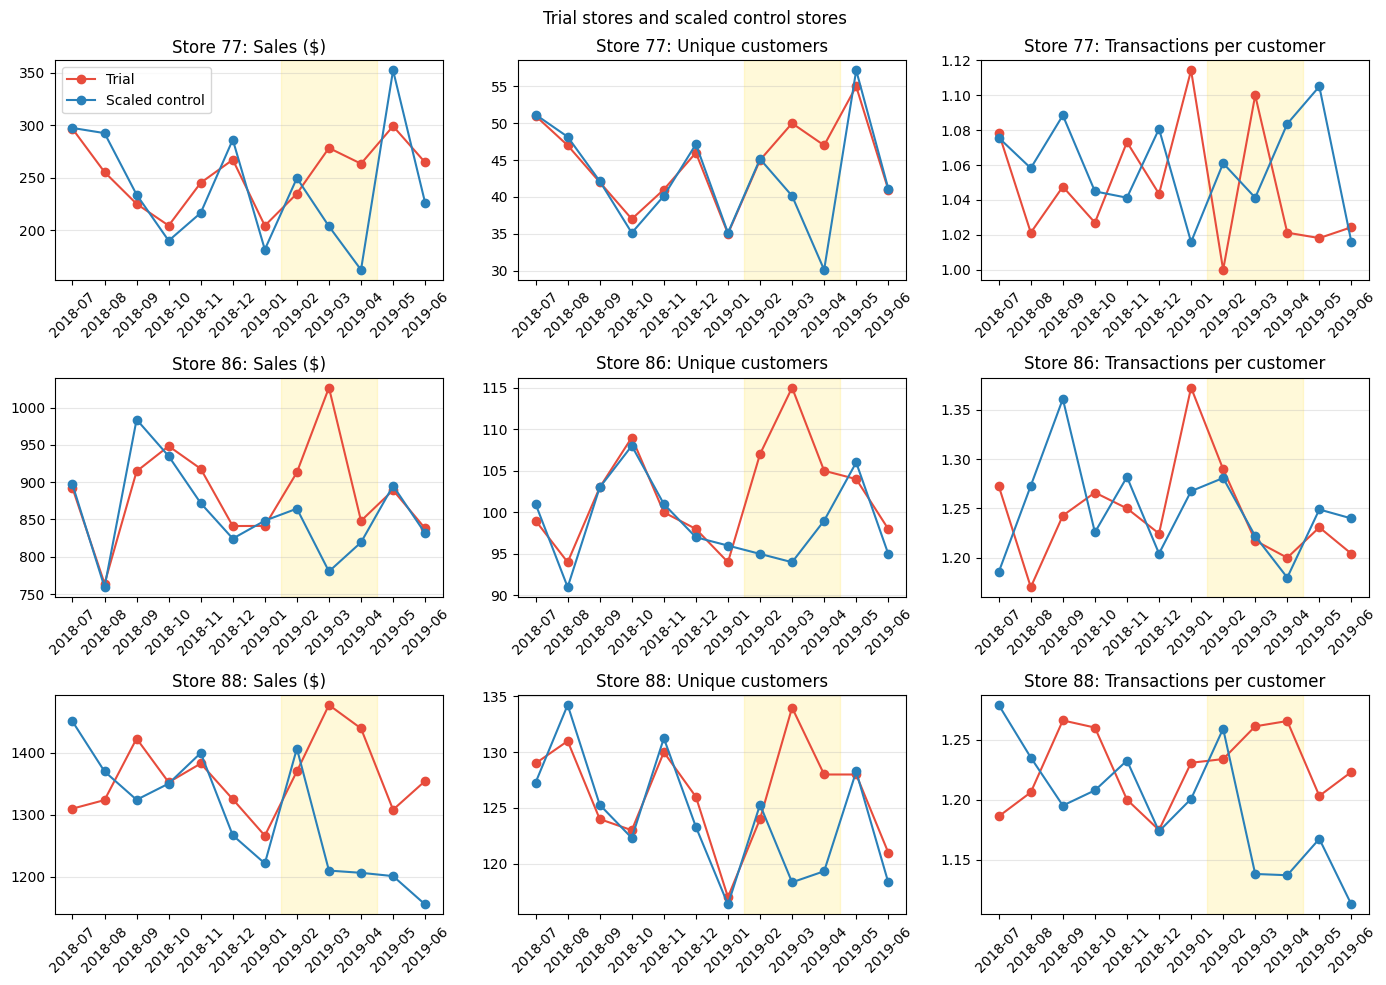

In [12]:
trial_results = monthly[monthly["MONTH"].isin(trial_months)]
comparison_metrics = ["sales", "customers", "transactions_per_customer"]
metric_names = {
    "sales": "Sales ($)",
    "customers": "Unique customers",
    "transactions_per_customer": "Transactions per customer",
}
scales = {}

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for row, trial_store in enumerate(trial_stores):
    control_store = control_map[trial_store]
    trial_before = before_trial[before_trial["STORE_NBR"] == trial_store]
    control_before = before_trial[before_trial["STORE_NBR"] == control_store]
    scales[trial_store] = {}

    for column, metric in enumerate(comparison_metrics):
        scale = trial_before[metric].mean() / control_before[metric].mean()
        scales[trial_store][metric] = scale
        ax = axes[row, column]

        for store, color, label in [
            (trial_store, "#E74C3C", "Trial"),
            (control_store, "#2980B9", "Scaled control"),
        ]:
            values = monthly[monthly["STORE_NBR"] == store].sort_values("MONTH")
            line_values = values[metric] if store == trial_store else values[metric] * scale
            ax.plot(values["MONTH"].astype(str), line_values, marker="o", color=color, label=label)

        ax.axvspan(6.5, 9.5, color="gold", alpha=0.15)
        ax.set_title(f"Store {trial_store}: {metric_names[metric]}")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", alpha=0.3)
        if row == 0 and column == 0:
            ax.legend()

plt.suptitle("Trial stores and scaled control stores")
plt.tight_layout()
plt.savefig(folder / "task2_fig2_trial_vs_control.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Check whether monthly changes stand out

For each metric, calculate how far the trial result is from its scaled control. We compare that difference with the range of differences seen in the seven pre-trial months. The range shown is a 95% prediction interval based on the t distribution. With only seven pre-trial months, and several months being tested, treat this as an indication rather than proof that the trial caused a change.

In [13]:
significance_results = {}

for trial_store in trial_stores:
    control_store = control_map[trial_store]
    significance_results[trial_store] = {}

    for metric in comparison_metrics:
        scale = scales[trial_store][metric]
        trial_before = before_trial[before_trial["STORE_NBR"] == trial_store].set_index("MONTH")[metric]
        control_before = before_trial[before_trial["STORE_NBR"] == control_store].set_index("MONTH")[metric]
        baseline_difference = (trial_before - control_before * scale) / (control_before * scale)

        month_count = baseline_difference.count()
        standard_deviation = baseline_difference.std()
        t_value = stats.t.ppf(0.975, month_count - 1)
        interval = t_value * standard_deviation * np.sqrt(1 + 1 / month_count)

        results = []
        for month in trial_months:
            trial_value = trial_results.loc[
                (trial_results["STORE_NBR"] == trial_store) & (trial_results["MONTH"] == month), metric
            ].iloc[0]
            control_value = trial_results.loc[
                (trial_results["STORE_NBR"] == control_store) & (trial_results["MONTH"] == month), metric
            ].iloc[0] * scale
            change = (trial_value / control_value - 1) * 100
            is_significant = change < -interval * 100 or change > interval * 100
            results.append({
                "month": str(month),
                "trial_value": trial_value,
                "control_value": control_value,
                "change_percent": change,
                "lower_limit": -interval * 100,
                "upper_limit": interval * 100,
                "outside_interval": is_significant,
            })

        significance_results[trial_store][metric] = pd.DataFrame(results)

for trial_store in trial_stores:
    print(f"Trial store {trial_store} vs control store {control_map[trial_store]}")
    for metric in comparison_metrics:
        print(metric_names[metric])
        display(significance_results[trial_store][metric].style.format({
            "trial_value": "{:,.2f}",
            "control_value": "{:,.2f}",
            "change_percent": "{:+.1f}%",
            "lower_limit": "{:+.1f}%",
            "upper_limit": "{:+.1f}%",
        }))

Trial store 77 vs control store 233
Sales ($)


,month,trial_value,control_value,change_percent,lower_limit,upper_limit,outside_interval
0,2019-02,235.00,249.76,-5.9%,-26.1%,+26.1%,False
1,2019-03,278.50,203.80,+36.7%,-26.1%,+26.1%,True
2,2019-04,263.50,162.35,+62.3%,-26.1%,+26.1%,True


Unique customers


,month,trial_value,control_value,change_percent,lower_limit,upper_limit,outside_interval
0,2019-02,45.00,45.15,-0.3%,-7.2%,+7.2%,False
1,2019-03,50.00,40.13,+24.6%,-7.2%,+7.2%,True
2,2019-04,47.00,30.10,+56.1%,-7.2%,+7.2%,True


Transactions per customer


...

,month,trial_value,control_value,change_percent,lower_limit,upper_limit,outside_interval
0,2019-02,"1,370.20","1,406.99",-2.6%,-15.0%,+15.0%,False
1,2019-03,"1,477.20","1,210.08",+22.1%,-15.0%,+15.0%,True
2,2019-04,"1,439.40","1,206.48",+19.3%,-15.0%,+15.0%,True


Unique customers


,month,trial_value,control_value,change_percent,lower_limit,upper_limit,outside_interval
0,2019-02,124.00,125.29,-1.0%,-4.1%,+4.1%,False
1,2019-03,134.00,118.33,+13.2%,-4.1%,+4.1%,True
2,2019-04,128.00,119.32,+7.3%,-4.1%,+4.1%,True


Transactions per customer


,month,trial_value,control_value,change_percent,lower_limit,upper_limit,outside_interval
0,2019-02,1.23,1.26,-2.0%,-12.0%,+12.0%,False
1,2019-03,1.26,1.14,+10.8%,-12.0%,+12.0%,False
2,2019-04,1.27,1.14,+11.3%,-12.0%,+12.0%,False


## 7. Plot monthly changes and summarize

A red bar is outside the pre-trial prediction interval. The three-month result compares total trial-period sales or customers with the scaled control.

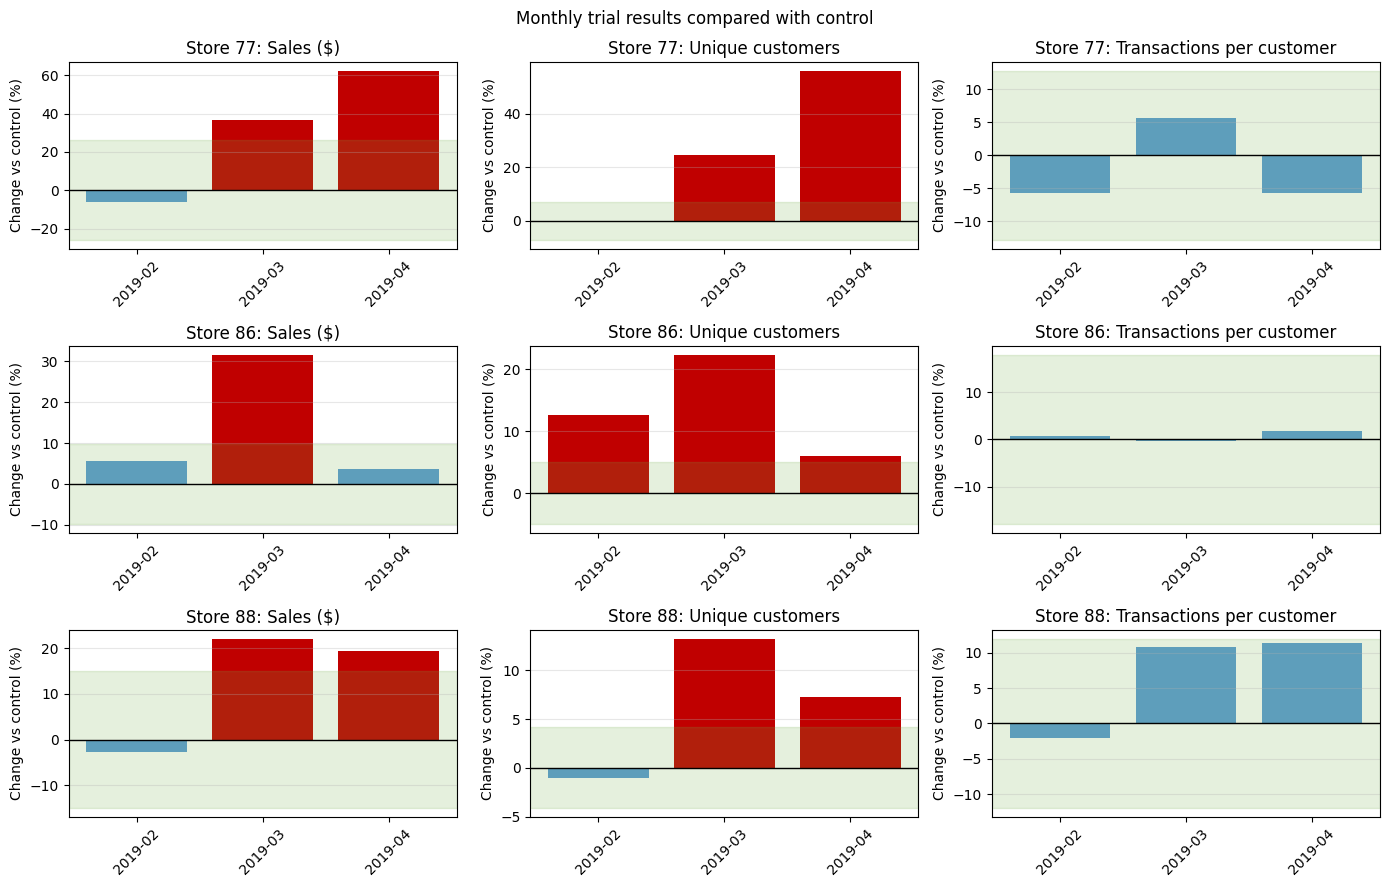

,trial_store,control_store,metric,trial_period_change,months_outside_interval
0,77,233,Sales ($),+26.2%,2
1,77,233,Unique customers,+23.1%,2
2,77,233,Transactions per customer,-2.0%,0
3,86,155,Sales ($),+13.2%,1
4,86,155,Unique customers,+13.5%,3
5,86,155,Transactions per customer,+0.7%,0
6,88,237,Sales ($),+12.1%,2
7,88,237,Unique customers,+6.4%,2
8,88,237,Transactions per customer,+6.7%,0


A difference outside the interval is an indication, not proof of cause and effect.


In [14]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
summary_rows = []

for row, trial_store in enumerate(trial_stores):
    for column, metric in enumerate(comparison_metrics):
        results = significance_results[trial_store][metric]
        colors = ["#C00000" if outside else "#5B9BD5" for outside in results["outside_interval"]]
        axes[row, column].bar(results["month"], results["change_percent"], color=colors)
        axes[row, column].axhline(0, color="black", linewidth=1)
        axes[row, column].axhspan(
            results["lower_limit"].iloc[0], results["upper_limit"].iloc[0],
            color="#70AD47", alpha=0.18,
        )
        axes[row, column].set_title(f"Store {trial_store}: {metric_names[metric]}")
        axes[row, column].tick_params(axis="x", rotation=45)
        axes[row, column].set_ylabel("Change vs control (%)")
        axes[row, column].grid(axis="y", alpha=0.3)

        if metric in ["sales", "customers"]:
            period_change = (
                results["trial_value"].sum() / results["control_value"].sum() - 1
            ) * 100
        else:
            period_change = results["change_percent"].mean()
        summary_rows.append({
            "trial_store": trial_store,
            "control_store": control_map[trial_store],
            "metric": metric_names[metric],
            "trial_period_change": period_change,
            "months_outside_interval": int(results["outside_interval"].sum()),
        })

plt.suptitle("Monthly trial results compared with control")
plt.tight_layout()
plt.savefig(folder / "task2_fig3_significance.png", dpi=150, bbox_inches="tight")
plt.show()

summary = pd.DataFrame(summary_rows)
display(summary.style.format({"trial_period_change": "{:+.1f}%"}))
print("A difference outside the interval is an indication, not proof of cause and effect.")

## Business summary: problem, action, and output

**Problem:** The business tested a new store layout in stores 77, 86 and 88 (Feb–Apr 2019). Did the trial stores sell more than similar stores without the new layout?

**Action:** For each trial store we picked a control store with a similar sales and customer pattern before the trial (Jul 2018 – Jan 2019): stores 233, 155 and 237. We scaled each control store to the trial store's size and compared sales, customers and transactions per customer in each trial month. A month counts as different when it falls outside the 95% range seen before the trial.

**Output:** Store 77: sales +26.2% and customers +23.1% (March and April outside the range). Store 86: customers +13.5% (all three months) and sales +13.2% (March only). Store 88: sales +12.1% and customers +6.4% (March and April). Transactions per customer did not change in any store, so the gain comes from more customers, not from more purchases per customer.

**Caution:** Only seven pre-trial months were available and several months were tested, so treat these results as an indication, not proof. The control store for Store 77 (233) had lower sales in March–April, which may make Store 77's gain look larger.